# Covarianza de estimadores de dos puntos en modelos de dilución de materia oscura

**Alcance:** solo materia, orden lineal y espacio real. Sigue el plan de `plan_proyecto.md`.

**Base teórica:** A. Avilés & J. Ferrara, *Dark Matter Dilution* (borrador). La dilución entra por la continuidad modificada, con $S=-g(t)H\bar\rho\,\delta$. A orden lineal solo cambia el factor de crecimiento $D_+$.

**Covarianza:** formalismo gaussiano. Es el término gaussiano de Steele & Smith (2026) y la fórmula de Wang et al. (2026) en espacio real.

| Paso | Contenido |
|---|---|
| 1 | Fondo ΛCDM de CLASS y crecimiento lineal $D_+(z)$, $f(z)$ con dilución |
| 2 | Espectro lineal (CLASS) $P_{\rm dil}(k)=[D_+^{\rm dil}/D_+^{\Lambda{\rm CDM}}]^2P_{\Lambda{\rm CDM}}(k)$ |
| 3 | Campos gaussianos en una caja periódica y trazadores discretos (lognormal + Poisson) |
| 4 | Estimadores: $P(k)$ y $\xi(r)$ con FFT; $\xi(r)$ por conteo de pares (PH, DP, Hamilton, LS) |
| 5 | Covarianza muestral (con factor de Hartlap) |
| 6 | Covarianza gaussiana analítica y comparación |
| 7 | Efecto de la dilución: S/N, estimadores, $\partial C/\partial g_0$ y sesgo |

**Qué se espera:** en un campo continuo, la dilución solo reescala la covarianza ($\propto D_+^4$). Lo no trivial viene del ruido de disparo $1/\bar n$, que **no** se diluye.

## 0. Configuración

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft
from scipy.integrate import solve_ivp, quad
from scipy.interpolate import interp1d
from scipy.spatial import cKDTree
from scipy.stats import chi2 as chi2_dist
from multiprocessing import Pool

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---- modo rápido: True solo para probar que todo corre (pocas realizaciones) ----
QUICK = False

# ---- cosmología de fondo (ΛCDM plano fijo, igual para todos los modelos) ----
Om0, Ob0, h, ns, sigma8 = 0.3, 0.045, 0.7, 0.965, 0.8

# ---- dilución: benchmark del borrador, ec. (3.13) ----
zt, dz_t = 2.0, 0.2
G0 = [0.0, 0.1, 0.2]      # 0 = ΛCDM; 0.1 sirve para validar la derivada; 0.2 = fiducial
G0_FID = 0.2
z_obs = 0.5               # redshift de trabajo

# ---- caja y malla ----
L, N = 1000.0, 128        # Mpc/h, malla N³
V, Vcell = L**3, (L / N)**3
kf, kNyq = 2*np.pi/L, np.pi*N/L

# ---- binning ----
KMAX = 0.30
k_edges = np.arange(0.5*kf, KMAX + 1e-9, 2*kf)     # bins de P(k)
r_edges = np.arange(20.0, 200.0 + 1e-9, 5.0)       # bins de ξ(r) [Mpc/h]
RMAX_PAIRS = 150.0                                 # conteo de pares hasta aquí (costo ∝ r³)

# ---- realizaciones y trazadores ----
Ns       = 40  if QUICK else 500    # campo continuo
Ns_tr    = 30  if QUICK else 300    # trazadores en malla (P y ξ con FFT)
NBAR     = [1e-4, 1e-3]             # (h/Mpc)³
NBAR_PAIRS = 5e-5                   # conteo de pares: N_D ≈ 5×10⁴
NS_PAIRS = 8   if QUICK else 60     # realizaciones con conteo de pares (por g0)
ALPHAS   = [1, 3]                   # N_R / N_D
N_WORKERS   = min(4, os.cpu_count())
FFT_WORKERS = 4

DATA = "data"; os.makedirs(DATA, exist_ok=True)
print(f"kf = {kf:.4f}, kNyq = {kNyq:.3f} h/Mpc, celda = {L/N:.2f} Mpc/h")
print(f"{len(k_edges)-1} bins en k, {len(r_edges)-1} bins en r")

kf = 0.0063, kNyq = 0.402 h/Mpc, celda = 7.81 Mpc/h
23 bins en k, 36 bins en r


## 1. Fondo ΛCDM (CLASS) y crecimiento lineal $D_+(z)$

**Fondo.** Se usa el fondo de **CLASS**: ΛCDM plano con fotones ($T_{\rm cmb}=2.7255$ K) y $N_{\rm eff}=3.044$ neutrinos sin masa. Es el mismo fondo con el que se calcula $P(k)$ en el paso 2, así que todo el cálculo es consistente. La dilución no cambia el fondo ($\bar S=0$, como en el borrador); el modelo es **ΛCDM + dilución**.

**Crecimiento.** La ecuación (3.2) del borrador, con $x=\ln a$, es
$$D'' + (2+\epsilon+g)D' - \tfrac32\Omega_m(a)(1+\Xi)D=0,\qquad
\epsilon=\frac{d\ln H}{d\ln a},\qquad
\Xi=-\frac{2}{3\Omega_m}\Big[g(2+\epsilon)+\frac{dg}{d\ln a}\Big].$$
$H(a)$ y $\Omega_m(a)=(\rho_{\rm cdm}+\rho_b)/\rho_{\rm crit}$ salen de CLASS, y $\epsilon$ se calcula derivando $\ln H$ (incluye la radiación). Se resuelve el sistema equivalente de primer orden, que es más estable:
$$\delta'=u-g\,\delta,\qquad u'=-(2+\epsilon)u+\tfrac32\Omega_m\delta .$$

**Condición inicial:** $z_{\rm ini}=99$, donde $g=0$. Se toman $D$ y $f$ del factor de crecimiento de CLASS en ese punto (modo creciente exacto con radiación), es decir $\delta=D_{\rm CLASS}$ y $u=f_{\rm CLASS}\,\delta$. **Los dos modelos parten de la misma condición inicial.**

In [2]:
from classy import Class
from scipy.interpolate import CubicSpline

cosmo = Class()
cosmo.set({
    "output": "mPk",
    "h": h,
    "omega_b": Ob0*h**2,
    "omega_cdm": (Om0 - Ob0)*h**2,
    "n_s": ns,
    "sigma8": sigma8,
    "P_k_max_h/Mpc": 20.0,
    "z_pk": 0.0,
})
cosmo.compute()

bg = cosmo.get_background()
x_all = -np.log1p(bg["z"])                          # ln a (CLASS lo da con z decreciente)
x_bg, iu = np.unique(x_all, return_index=True)      # orden creciente y sin puntos repetidos
m = x_bg > -np.log1p(1e4)                           # fondo desde z = 10⁴ hasta hoy
x_bg, iu = x_bg[m], iu[m]
lnH = CubicSpline(x_bg, np.log(bg["H [1/Mpc]"][iu]))
Om_sp = CubicSpline(x_bg, ((bg["(.)rho_cdm"] + bg["(.)rho_b"])/bg["(.)rho_crit"])[iu])
D_cl = CubicSpline(x_bg, bg["gr.fac. D"][iu])       # crecimiento de CLASS (normalizado a 1 hoy)
f_cl = CubicSpline(x_bg, bg["gr.fac. f"][iu])
dlnH = lnH.derivative()

def Om(x):   return Om_sp(x)                         # Ω_m(a) de materia que se agrupa
def eps(x):  return dlnH(x)                          # d ln H / d ln a
print(f"CLASS: Ω_m0 = {cosmo.Omega_m():.4f}, Ω_r0 = {bg['Omega_r(z)'][-1]:.2e}, N_eff = {cosmo.Neff():.3f}")
print(f"ε(z=0) = {eps(0.0):.4f}  (sin radiación: {-1.5*Om(0.0):.4f});"
      f"  ε(z=99) = {eps(-np.log(100)):.4f}  (sin radiación: {-1.5*Om(-np.log(100)):.4f})")

CLASS: Ω_m0 = 0.3000, Ω_r0 = 8.54e-05, N_eff = 3.044
ε(z=0) = -0.4502  (sin radiación: -0.4500);  ε(z=99) = -1.5138  (sin radiación: -1.4585)


In [3]:
def g_of_z(z, g0):
    return 0.5*g0*(1 - np.tanh((z - zt)/dz_t))

def dg_dlna(z, g0):                     # d ln a = -dz/(1+z)
    x = np.clip((z - zt)/dz_t, -300, 300)         # evita overflow en cosh a z alto
    dgdz = -0.5*g0/dz_t / np.cosh(x)**2
    return -(1 + z)*dgdz

Z_INI = 99.0
X_INI = -np.log1p(Z_INI)
assert g_of_z(Z_INI, max(G0)) < 1e-12               # la dilución está apagada al inicio
Y_INI = [float(D_cl(X_INI)), float(f_cl(X_INI)*D_cl(X_INI))]   # δ = D, u = f D (g = 0)

def solve_growth(g0):
    # sistema de primer orden (δ, u) con el fondo de CLASS
    def rhs(x, y):
        z = np.exp(-x) - 1
        d, u = y
        return [u - g_of_z(z, g0)*d, -(2 + eps(x))*u + 1.5*Om(x)*d]
    sol = solve_ivp(rhs, [X_INI, 0.0], Y_INI, dense_output=True, rtol=1e-10, atol=1e-13)
    def D(z):
        return sol.sol(-np.log1p(z))[0]
    def f(z):
        d, u = sol.sol(-np.log1p(z))
        return u/d - g_of_z(z, g0)
    return D, f

def solve_growth_2nd(g0):
    # forma de segundo orden con Θ y Ξ (solo para validar)
    def rhs(x, y):
        z = np.exp(-x) - 1
        D, Dp = y
        g, e = g_of_z(z, g0), eps(x)
        coef = 1.5*Om(x) - g*(2 + e) - dg_dlna(z, g0)   # = (3/2)Ωm(1+Ξ)
        return [Dp, -(2 + e + g)*Dp + coef*D]
    sol = solve_ivp(rhs, [X_INI, 0.0], Y_INI, dense_output=True, rtol=1e-10, atol=1e-13)
    return lambda z: sol.sol(-np.log1p(z))[0]

GROW = {g0: solve_growth(g0) for g0 in G0}
D = {g0: GROW[g0][0] for g0 in G0}
f = {g0: GROW[g0][1] for g0 in G0}

# cociente de amplitudes P_dil / P_ΛCDM a z_obs
RATIO = {g0: (D[g0](z_obs)/D[0.0](z_obs))**2 for g0 in G0}
for g0 in G0:
    print(f"g0 = {g0:.1f}:  D(z_obs)/D_ΛCDM = {D[g0](z_obs)/D[0.0](z_obs):.4f},"
          f"  P_dil/P_ΛCDM = {RATIO[g0]:.4f},  f(z_obs) = {f[g0](z_obs):.4f}")

g0 = 0.0:  D(z_obs)/D_ΛCDM = 1.0000,  P_dil/P_ΛCDM = 1.0000,  f(z_obs) = 0.7491
g0 = 0.1:  D(z_obs)/D_ΛCDM = 0.9455,  P_dil/P_ΛCDM = 0.8940,  f(z_obs) = 0.6768
g0 = 0.2:  D(z_obs)/D_ΛCDM = 0.8944,  P_dil/P_ΛCDM = 0.7999,  f(z_obs) = 0.6055


### Validaciones del crecimiento

In [4]:
zz = np.array([0.0, 0.5, 1.0, 2.0, 5.0, 20.0])
xx = -np.log1p(zz)

# (a) g0 = 0 contra el factor de crecimiento de CLASS (mismo fondo, con radiación)
print("(a) |D/D_CLASS − 1| (g0=0):", np.array2string(np.abs(D[0.0](zz)/D_cl(xx) - 1), precision=2))
print("    |f/f_CLASS − 1| (g0=0):", np.array2string(np.abs(f[0.0](zz)/f_cl(xx) - 1), precision=2))

# (b) f ≈ Ωm(z)^0.55 para g0 = 0 (aproximación conocida)
for z in [0.0, 0.5, 1.0]:
    print(f"(b) z={z}: f = {f[0.0](z):.4f},  Ωm^0.55 = {Om(-np.log1p(z))**0.55:.4f}")

# (c) forma de 1er orden vs. 2º orden (con Ξ)
D2 = solve_growth_2nd(G0_FID)
print("(c) |D_1er/D_2do − 1| (g0=0.2):", max(abs(D[G0_FID](z)/D2(z) - 1) for z in zz))

(a) |D/D_CLASS − 1| (g0=0): [8.64e-10 5.31e-10 1.65e-09 2.02e-09 2.17e-10 2.23e-10]
    |f/f_CLASS − 1| (g0=0): [8.23e-10 1.06e-10 4.11e-10 5.75e-10 1.26e-11 1.24e-11]
(b) z=0.0: f = 0.5128,  Ωm^0.55 = 0.5157
(b) z=0.5: f = 0.7491,  Ωm^0.55 = 0.7489
(b) z=1.0: f = 0.8690,  Ωm^0.55 = 0.8685
(c) |D_1er/D_2do − 1| (g0=0.2): 6.148681563900027e-11


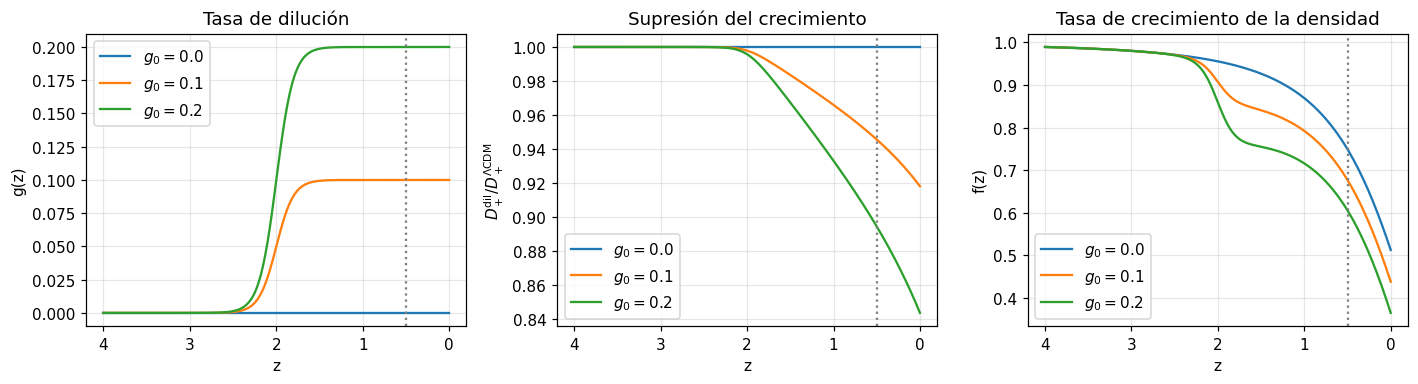

In [5]:
zplot = np.linspace(0, 4, 300)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for g0 in G0:
    ax[0].plot(zplot, g_of_z(zplot, g0), label=f"$g_0={g0}$")
    ax[1].plot(zplot, D[g0](zplot)/D[0.0](zplot), label=f"$g_0={g0}$")
    ax[2].plot(zplot, f[g0](zplot), label=f"$g_0={g0}$")
ax[0].set(xlabel="z", ylabel="g(z)", title="Tasa de dilución")
ax[1].set(xlabel="z", ylabel=r"$D_+^{\rm dil}/D_+^{\Lambda\rm CDM}$", title="Supresión del crecimiento")
ax[2].set(xlabel="z", ylabel="f(z)", title="Tasa de crecimiento de la densidad")
for a in ax:
    a.invert_xaxis(); a.axvline(z_obs, color="gray", ls=":"); a.legend()
plt.tight_layout(); plt.show()

## 2. Espectro de potencias lineal

$P_{\Lambda\rm CDM}(k,z=0)$ se calcula con **CLASS** (`classy`), con el mismo fondo del paso 1 y normalizado a $\sigma_8=0.8$ (CLASS ajusta $A_s$ internamente).

Como los dos modelos comparten la condición inicial:
$$P_{\rm model}(k;g_0,z)=P_{\Lambda\rm CDM}(k,0)\left[\frac{D_+^{g_0}(z)}{D_+^{\Lambda\rm CDM}(0)}\right]^2 .$$

In [6]:
def sigma_R(kk, Pk, R=8.0):
    x = kk*R
    W = 3*(np.sin(x) - x*np.cos(x))/x**3
    return np.sqrt(np.trapezoid(kk**3*Pk*W**2/(2*np.pi**2), np.log(kk)))

# se usa el mismo objeto `cosmo` del paso 1 (mismo fondo)

k_lin = np.logspace(-4, 1.2, 3000)                                  # h/Mpc
P_lin0 = np.array([cosmo.pk_lin(k*h, 0.0) for k in k_lin])*h**3     # (Mpc/h)³
print(f"CLASS: σ8 = {cosmo.sigma8():.4f} (integral propia: {sigma_R(k_lin, P_lin0):.4f}),"
      f"  Ω_m = {cosmo.Omega_m():.4f},  r_s(drag) = {cosmo.rs_drag()*h:.1f} Mpc/h")
cosmo.struct_cleanup(); cosmo.empty()

_logP = interp1d(np.log(k_lin), np.log(P_lin0), bounds_error=False, fill_value=-np.inf)
def P_model(k, g0, z=z_obs):
    k = np.asarray(k, float)
    out = np.zeros_like(k)
    m = k > 0
    out[m] = np.exp(_logP(np.log(k[m]))) * (D[g0](z)/D[0.0](0.0))**2
    return out

CLASS: σ8 = 0.8000 (integral propia: 0.8000),  Ω_m = 0.3000,  r_s(drag) = 102.3 Mpc/h


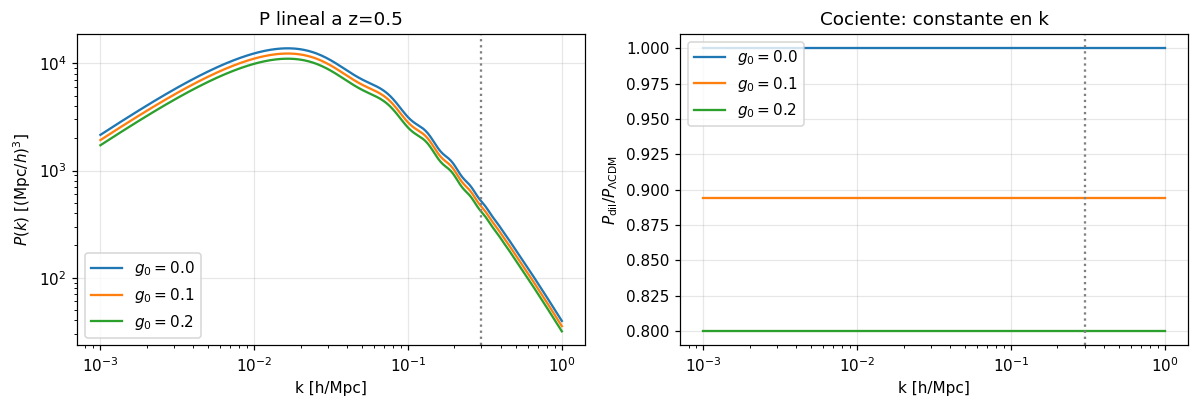

In [7]:
kk = np.logspace(-3, 0, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for g0 in G0:
    ax[0].loglog(kk, P_model(kk, g0), label=f"$g_0={g0}$")
    ax[1].semilogx(kk, P_model(kk, g0)/P_model(kk, 0.0), label=f"$g_0={g0}$")
ax[0].set(xlabel="k [h/Mpc]", ylabel=r"$P(k)\ [({\rm Mpc}/h)^3]$", title=f"P lineal a z={z_obs}")
ax[1].set(xlabel="k [h/Mpc]", ylabel=r"$P_{\rm dil}/P_{\Lambda\rm CDM}$", title="Cociente: constante en k")
for a in ax: a.axvline(KMAX, color="gray", ls=":"); a.legend()
plt.tight_layout(); plt.show()

## 3. Malla, bins y campos gaussianos

**Convenciones** (numpy/scipy, FFT sin normalizar):
- $\delta_k^{\rm FFT}=\sum_x\delta(x)e^{-ik\cdot x}$ y $\hat P(k)=|\delta_k^{\rm FFT}|^2V_{\rm cell}^2/V$.
- Campo gaussiano: $\delta_k^{\rm FFT}=\mathrm{FFT}[w]\sqrt{P(k)/V_{\rm cell}}$, con $w\sim\mathcal N(0,1)$ en cada celda.
- `rfftn` guarda solo la mitad de los modos. Por eso cada modo pesa 2, salvo en los planos $k_z=0$ y $k_z=$ Nyquist. Con esos pesos, $N_k$ cuenta los modos de la malla completa.
- $\xi$ en la malla: $\hat\xi(r)=\frac1{N^3}\sum_x\delta(x)\delta(x+r)$, promediada en cada cáscara de $r$ (con periodicidad).

In [8]:
kx = 2*np.pi*fft.fftfreq(N, d=L/N)
kz = 2*np.pi*fft.rfftfreq(N, d=L/N)
KX, KY, KZ = np.meshgrid(kx, kx, kz, indexing="ij")
K3 = np.sqrt(KX**2 + KY**2 + KZ**2)
W3 = np.full(K3.shape, 2.0); W3[..., 0] = 1.0; W3[..., -1] = 1.0    # peso para contar la malla completa
del KX, KY, KZ

nk = len(k_edges) - 1
kidx = np.digitize(K3, k_edges) - 1
ksel = np.flatnonzero((kidx >= 0) & (kidx < nk))
kidx_s, W3_s = kidx.ravel()[ksel], W3.ravel()[ksel]
N_k = np.bincount(kidx_s, weights=W3_s, minlength=nk)                     # modos por bin
k_b = np.bincount(kidx_s, weights=W3_s*K3.ravel()[ksel], minlength=nk)/N_k  # k medio por bin

def bin_k(arr3):
    return np.bincount(kidx_s, weights=W3_s*arr3.ravel()[ksel], minlength=nk)/N_k

# distancias en la malla real (periódica)
ix = np.minimum(np.arange(N), N - np.arange(N))*(L/N)
R3 = np.sqrt(ix[:, None, None]**2 + ix[None, :, None]**2 + ix[None, None, :]**2)
nr = len(r_edges) - 1
ridx = np.digitize(R3, r_edges) - 1
rsel = np.flatnonzero((ridx >= 0) & (ridx < nr))
ridx_s = ridx.ravel()[rsel]
n_r = np.bincount(ridx_s, minlength=nr).astype(float)
r_b = np.bincount(ridx_s, weights=R3.ravel()[rsel], minlength=nr)/n_r

def bin_r(arr3):
    return np.bincount(ridx_s, weights=arr3.ravel()[rsel], minlength=nr)/n_r

# J_i(k) = promedio de cos(k·r) sobre los puntos r de la malla en el bin i
# (sirve para la covarianza gaussiana EXACTA de ξ medida en la malla)
J = np.empty((nr, K3.size), dtype=np.float32)
for i in range(nr):
    mask = (ridx == i).astype(np.float64)
    J[i] = (fft.rfftn(mask, workers=FFT_WORKERS).real/n_r[i]).ravel()
del R3, mask
print(f"N_k: de {N_k[0]:.0f} a {N_k[-1]:.0f} modos;  bins de r: {nr}")

N_k: de 80 a 52064 modos;  bins de r: 36


In [9]:
def white_k(seed):
    # FFT de ruido blanco real (la simetría hermítica queda garantizada)
    w = np.random.default_rng(seed).standard_normal((N, N, N))
    return fft.rfftn(w, workers=FFT_WORKERS)

def P_grid(g0):
    Pg = P_model(K3, g0)
    Pg[0, 0, 0] = 0.0                      # sin modo k = 0
    return Pg

def xi_grid_from_P(Pg):
    # ξ(r) = (1/V) Σ_k P(k) e^{ik·r}, en la malla
    return fft.irfftn(Pg, s=(N,)*3, workers=FFT_WORKERS)*N**3/V

def measure(dk):
    # P(k) y ξ(r) binneados a partir de δ_k (FFT sin normalizar)
    p3 = np.abs(dk)**2
    Pb = bin_k(p3)*Vcell**2/V
    xi3 = fft.irfftn(p3, s=(N,)*3, workers=FFT_WORKERS)/N**3
    return Pb, bin_r(xi3)

# modelos del campo continuo (binneados exactamente como la medición)
PG   = {g0: P_grid(g0) for g0 in G0}
SQ   = {g0: np.sqrt(PG[g0]/Vcell) for g0 in G0}
PMOD = {g0: bin_k(PG[g0]) for g0 in G0}
XMOD = {g0: bin_r(xi_grid_from_P(PG[g0])) for g0 in G0}

### Trazadores discretos: lognormal + Poisson

Si se muestrea Poisson directamente de un campo gaussiano, aparecen celdas con $\delta<-1$, porque la celda de 7.8 Mpc/h es pequeña. La técnica estándar es usar un **campo lognormal** con el $\xi$ objetivo:
$$\xi_G=\ln(1+\xi_{\rm obj}),\qquad n_{\rm cel}\sim{\rm Poisson}\big[\bar nV_{\rm cell}\,e^{\delta_G-\sigma_G^2/2}\big],\qquad \xi_{\rm LN}=e^{\xi_G}-1 .$$
Así el trazador tiene, por construcción, $P_{\rm tr}\simeq P_{\rm model}$ (lineal). El modelo exacto en la malla es $\xi_{\rm LN}$; la única diferencia es el recorte de $P_G<0$, que se reporta.

**Medición en la malla:** se usan los conteos por celda directamente (NGP, sin ventana extra). Así $\hat P-1/\hat{\bar n}$ es un estimador insesgado de $P_{\rm LN}$ en la malla. Para el conteo de pares, cada partícula se coloca uniforme dentro de su celda.

In [10]:
def lognormal_setup(g0):
    xi_obj = xi_grid_from_P(PG[g0])
    xi_G = np.log1p(xi_obj)
    PGg = fft.rfftn(xi_G, workers=FFT_WORKERS).real*Vcell
    PGg[0, 0, 0] = 0.0
    frac_neg = np.mean(PGg < 0)
    PGg = np.clip(PGg, 0, None)
    xi_G2 = xi_grid_from_P(PGg)
    sig2 = xi_G2.ravel()[0]                       # varianza del campo gaussiano en la malla
    xi_LN = np.expm1(xi_G2)
    PLN = fft.rfftn(xi_LN, workers=FFT_WORKERS).real*Vcell
    PLN[0, 0, 0] = 0.0
    return dict(sq=np.sqrt(PGg/Vcell), sig2=sig2, PLN=PLN,
                Pmod=bin_k(PLN), Xmod=bin_r(xi_LN), frac_neg=frac_neg)

TR = {g0: lognormal_setup(g0) for g0 in G0}
for g0 in G0:
    print(f"g0={g0}: σ_G² = {TR[g0]['sig2']:.3f}, fracción P_G<0 recortada = {TR[g0]['frac_neg']:.2e},"
          f"  max|P_LN/P_model - 1| (k<KMAX) = {np.max(np.abs(TR[g0]['Pmod']/PMOD[g0] - 1)):.2e}")

def tracer_counts(wk, g0, nbar, rng):
    dG = fft.irfftn(wk*TR[g0]["sq"], s=(N,)*3, workers=FFT_WORKERS)
    lam = nbar*Vcell*np.exp(dG - 0.5*TR[g0]["sig2"])
    return rng.poisson(lam)

def tracer_measure(counts):
    nbar_hat = counts.sum()/V
    delta = counts/(nbar_hat*Vcell) - 1.0
    Pb, Xb = measure(fft.rfftn(delta, workers=FFT_WORKERS))
    return Pb - 1/nbar_hat, Xb, nbar_hat

def counts_to_positions(counts, rng):
    idx = np.repeat(np.arange(counts.size), counts.ravel())
    ijk = np.column_stack(np.unravel_index(idx, counts.shape)).astype(float)
    return (ijk + rng.uniform(size=ijk.shape))*(L/N)

g0=0.0: σ_G² = 0.678, fracción P_G<0 recortada = 0.00e+00,  max|P_LN/P_model - 1| (k<KMAX) = 4.83e-07
g0=0.1: σ_G² = 0.624, fracción P_G<0 recortada = 0.00e+00,  max|P_LN/P_model - 1| (k<KMAX) = 3.94e-07
g0=0.2: σ_G² = 0.574, fracción P_G<0 recortada = 0.00e+00,  max|P_LN/P_model - 1| (k<KMAX) = 3.21e-07


### Validación con una realización

trazadores: N = 1000755, n̄ esperado = 1000000


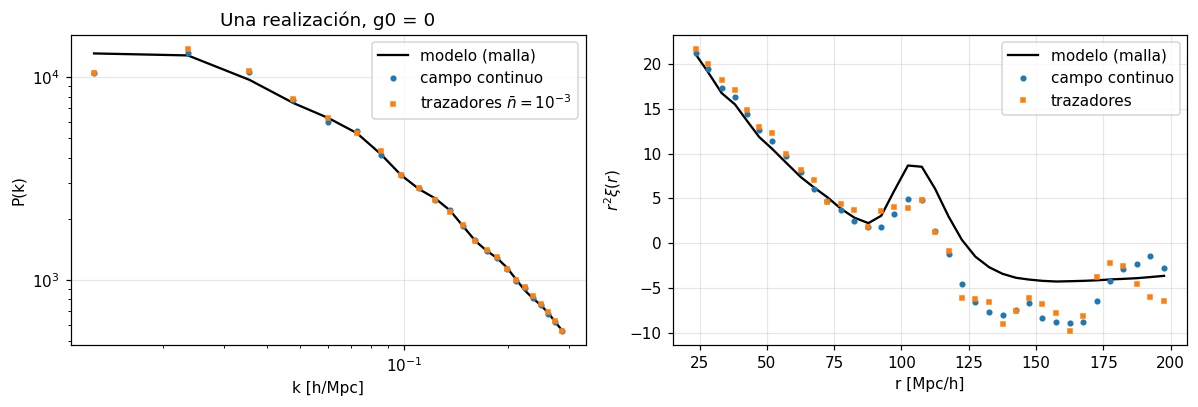

In [11]:
wk = white_k(12345)
Pb, Xb = measure(wk*SQ[0.0])
cnt = tracer_counts(wk, 0.0, 1e-3, np.random.default_rng(1))
Pt, Xt, nb_hat = tracer_measure(cnt)
print(f"trazadores: N = {cnt.sum()}, n̄ esperado = {1e-3*V:.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(k_b, PMOD[0.0], "k-", label="modelo (malla)")
ax[0].loglog(k_b, Pb, "o", ms=3, label="campo continuo")
ax[0].loglog(k_b, Pt, "s", ms=3, label=r"trazadores $\bar n=10^{-3}$")
ax[0].set(xlabel="k [h/Mpc]", ylabel="P(k)", title="Una realización, g0 = 0")
ax[1].plot(r_b, r_b**2*XMOD[0.0], "k-", label="modelo (malla)")
ax[1].plot(r_b, r_b**2*Xb, "o", ms=3, label="campo continuo")
ax[1].plot(r_b, r_b**2*Xt, "s", ms=3, label="trazadores")
ax[1].set(xlabel="r [Mpc/h]", ylabel=r"$r^2\xi(r)$")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 4. Ensambles de realizaciones

Se usa la **misma semilla** para todos los $g_0$. En el campo continuo eso hace que $\delta_{\rm dil}=\sqrt{\rm RATIO}\,\delta_{\Lambda\rm CDM}$ exactamente. Es una prueba de sanidad, no un resultado.

### 4a. Campo continuo

In [12]:
t0 = time.time()
Pc = {g0: np.empty((Ns, nk)) for g0 in G0}
Xc = {g0: np.empty((Ns, nr)) for g0 in G0}
for s in range(Ns):
    wk = white_k(s)
    for g0 in G0:
        Pc[g0][s], Xc[g0][s] = measure(wk*SQ[g0])
print(f"{Ns} realizaciones × {len(G0)} modelos en {time.time() - t0:.0f} s")
np.savez(f"{DATA}/continuo.npz", k_b=k_b, r_b=r_b, N_k=N_k,
         **{f"P_{g0}": Pc[g0] for g0 in G0}, **{f"X_{g0}": Xc[g0] for g0 in G0})

500 realizaciones × 3 modelos en 65 s


### 4b. Trazadores en la malla (lognormal + Poisson)

In [13]:
t0 = time.time()
Pt = {(g0, nb): np.empty((Ns_tr, nk)) for g0 in G0 for nb in NBAR}
Xt = {(g0, nb): np.empty((Ns_tr, nr)) for g0 in G0 for nb in NBAR}
for s in range(Ns_tr):
    wk = white_k(s)
    for ig, g0 in enumerate(G0):
        for inb, nb in enumerate(NBAR):
            rng = np.random.default_rng([s, ig, inb])
            Pt[g0, nb][s], Xt[g0, nb][s], _ = tracer_measure(tracer_counts(wk, g0, nb, rng))
print(f"{Ns_tr} realizaciones × {len(G0)} modelos × {len(NBAR)} densidades en {time.time() - t0:.0f} s")
np.savez(f"{DATA}/trazadores.npz", k_b=k_b, r_b=r_b,
         **{f"P_{g0}_{nb}": Pt[g0, nb] for g0 in G0 for nb in NBAR},
         **{f"X_{g0}_{nb}": Xt[g0, nb] for g0 in G0 for nb in NBAR})

300 realizaciones × 3 modelos × 2 densidades en 239 s


### 4c. Conteo de pares: estimadores de $\xi(r)$

Igual que en la práctica 05, pero con `cKDTree(boxsize=L)` por la periodicidad. Los conteos se normalizan por pares ordenados:
$$\mathrm{PH}=\frac{DD}{RR}-1,\quad \mathrm{DP}=\frac{DD}{DR}-1,\quad \mathrm{Ham}=\frac{DD\,RR}{DR^2}-1,\quad \mathrm{LS}=\frac{DD-2DR+RR}{RR},\quad \mathrm{nat}=\frac{DD}{RR_{\rm analítico}}-1,$$
con $RR_{\rm analítico}=V_{\rm cáscara}/V$ en la caja periódica.

Los catálogos aleatorios tienen $N_R=\alpha N_D$ y son **fijos** (uno por $\alpha$), como en un análisis real. $RR$ se calcula una sola vez. **Consecuencia:** el ruido de $RR$ y $DR$ es el mismo en todas las realizaciones, así que aparece como un **sesgo** que no se promedia (baja con $\alpha$), y no como varianza. El estimador natural no usa aleatorios y no tiene ese problema. Las realizaciones se reparten en `N_WORKERS` procesos.

In [14]:
rp_edges = r_edges[r_edges <= RMAX_PAIRS + 1e-9]
nrp = len(rp_edges) - 1
RR_AN = 4*np.pi/3*(rp_edges[1:]**3 - rp_edges[:-1]**3)/V
ND_EXP = int(NBAR_PAIRS*V)

t0 = time.time()
RAND = {}
for a in ALPHAS:
    NR = a*ND_EXP
    R = np.random.default_rng(999 + a).uniform(0, L, (NR, 3))
    tR = cKDTree(R, boxsize=L)
    RR = np.diff(tR.count_neighbors(tR, rp_edges)).astype(float)/(NR*(NR - 1))
    RAND[a] = (tR, NR, RR)
print(f"RR para α = {ALPHAS} en {time.time() - t0:.0f} s")

def pair_worker(args):
    s, g0 = args
    rng = np.random.default_rng([s, int(round(10*g0)), 77])
    cnt = tracer_counts(white_k(s), g0, NBAR_PAIRS, rng)
    pos = counts_to_positions(cnt, rng)
    ND = len(pos)
    tD = cKDTree(pos, boxsize=L)
    DD = np.diff(tD.count_neighbors(tD, rp_edges)).astype(float)/(ND*(ND - 1))
    out = {"nat": DD/RR_AN - 1}
    for a in ALPHAS:
        tR, NR, RR = RAND[a]
        DR = np.diff(tD.count_neighbors(tR, rp_edges)).astype(float)/(ND*NR)
        out[f"PH_a{a}"]  = DD/RR - 1
        out[f"DP_a{a}"]  = DD/DR - 1
        out[f"Ham_a{a}"] = DD*RR/DR**2 - 1
        out[f"LS_a{a}"]  = (DD - 2*DR + RR)/RR
    return out

G_PAIRS = [0.0, G0_FID]
t0 = time.time()
tasks = [(s, g0) for g0 in G_PAIRS for s in range(NS_PAIRS)]
with Pool(N_WORKERS) as pool:
    res = pool.map(pair_worker, tasks, chunksize=1)
EST_NAMES = list(res[0].keys())
EST = {g0: {e: np.array([r[e] for (s, gg), r in zip(tasks, res) if gg == g0]) for e in EST_NAMES}
       for g0 in G_PAIRS}
print(f"{len(tasks)} conteos de pares en {time.time() - t0:.0f} s ({N_WORKERS} procesos)")
np.savez(f"{DATA}/pares.npz", rp_edges=rp_edges,
         **{f"{e}_{g0}": EST[g0][e] for g0 in G_PAIRS for e in EST_NAMES})

RR para α = [1, 3] en 20 s


120 conteos de pares en 370 s (4 procesos)


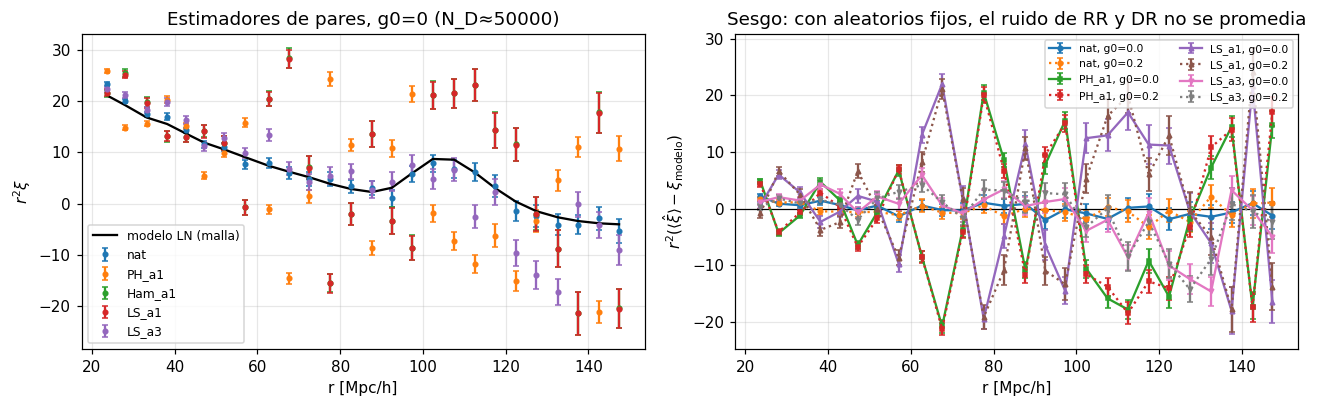

In [15]:
# validación: promedio de los estimadores contra el modelo lognormal de la malla
rp_b = r_b[:nrp]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for e in ["nat", f"PH_a{ALPHAS[0]}", f"Ham_a{ALPHAS[0]}", f"LS_a{ALPHAS[0]}", f"LS_a{ALPHAS[-1]}"]:
    m = EST[0.0][e].mean(0); s_ = EST[0.0][e].std(0)/np.sqrt(NS_PAIRS)
    ax[0].errorbar(rp_b, rp_b**2*m, rp_b**2*s_, fmt="o", ms=3, capsize=2, label=e)
ax[0].plot(rp_b, rp_b**2*TR[0.0]["Xmod"][:nrp], "k-", label="modelo LN (malla)")
ax[0].set(xlabel="r [Mpc/h]", ylabel=r"$r^2\xi$", title=f"Estimadores de pares, g0=0 (N_D≈{ND_EXP})")
ax[0].legend(fontsize=8)
for e, mk in [("nat", "o"), (f"PH_a{ALPHAS[0]}", "s"), (f"LS_a{ALPHAS[0]}", "^"), (f"LS_a{ALPHAS[-1]}", "v")]:
    for g0, ls in [(0.0, "-"), (G0_FID, ":")]:
        d = EST[g0][e] - TR[g0]["Xmod"][:nrp]
        ax[1].errorbar(rp_b, rp_b**2*d.mean(0), rp_b**2*d.std(0)/np.sqrt(NS_PAIRS),
                       fmt=mk + ls, ms=3, capsize=2, label=f"{e}, g0={g0}")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xlabel="r [Mpc/h]", ylabel=r"$r^2(\langle\hat\xi\rangle-\xi_{\rm modelo})$",
          title="Sesgo: con aleatorios fijos, el ruido de RR y DR no se promedia")
ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 5. Covarianza muestral

$$\hat C_{ij}=\frac{1}{N_s-1}\sum_s(d_s-\bar d)_i(d_s-\bar d)_j,\qquad
\hat\Psi=\frac{N_s-n_b-2}{N_s-1}\hat C^{-1}\ \text{(Hartlap)} .$$
El error relativo de la diagonal es $\simeq\sqrt{2/(N_s-1)}$.

In [16]:
def sample_cov(X):
    m = X.mean(0)
    C = (X - m).T @ (X - m)/(len(X) - 1)
    return m, C

def corr(C):
    d = np.sqrt(np.diag(C))
    return C/np.outer(d, d)

def hartlap_prec(C, Ns_):
    nb = C.shape[0]
    assert Ns_ > nb + 2, "hacen falta más realizaciones que bins + 2"
    return (Ns_ - nb - 2)/(Ns_ - 1)*np.linalg.inv(C)

SC_P  = {g0: sample_cov(Pc[g0])[1] for g0 in G0}
SC_X  = {g0: sample_cov(Xc[g0])[1] for g0 in G0}
SCt_P = {key: sample_cov(Pt[key])[1] for key in Pt}
SCt_X = {key: sample_cov(Xt[key])[1] for key in Xt}
print("error relativo esperado de la diagonal:",
      f"continuo {np.sqrt(2/(Ns-1)):.3f}, trazadores {np.sqrt(2/(Ns_tr-1)):.3f}")

error relativo esperado de la diagonal: continuo 0.063, trazadores 0.082


## 6. Covarianza gaussiana analítica

**P(k).** Es el término gaussiano de Steele & Smith (ec. 13, 17) y de Wang et al. (ec. 2.3–2.6) en espacio real, promediado exactamente como la medición:
$$C^P_{ii}=\frac{2}{N_k^2}\sum_{k\in i}\big[P(k)+1/\bar n\big]^2,\qquad C^P_{i\neq j}=0 .$$

**ξ(r).** En la malla, $\hat\xi_i=\frac1V\sum_k\hat P(k)J_i(k)$, con $J_i(k)=\langle\cos k\!\cdot\!r\rangle_{r\in i}$. Por lo tanto
$$C^\xi_{ij}=\frac{2}{V^2}\sum_{k}J_i(k)J_j(k)\big[P(k)+1/\bar n\big]^2 .$$
Es exacta para un campo gaussiano medido en la malla. Su límite continuo es la fórmula de Grieb et al. (2016), $\frac{2}{V}\int\frac{k^2dk}{2\pi^2}\bar j_0(kr_i)\bar j_0(kr_j)[P+1/\bar n]^2$.

**Trazadores.** Se usa $P_{\rm LN}+1/\bar n$. Las desviaciones respecto a la covarianza muestral miden la parte **no gaussiana**: el trispectro lognormal y los términos de Poisson de orden superior.

In [17]:
W3f = W3.ravel()
def cov_P_gauss(Pg3, nbar=None):
    Pt3 = Pg3 + (1/nbar if nbar else 0.0)
    Pt3 = np.where(K3 > 0, Pt3, 0.0)
    return np.diag(2/N_k**2*np.bincount(kidx_s, weights=W3_s*(Pt3.ravel()[ksel])**2, minlength=nk))

def cov_xi_gauss(Pg3, nbar=None):
    Pt3 = Pg3 + (1/nbar if nbar else 0.0)
    Pt3 = np.where(K3 > 0, Pt3, 0.0).ravel()
    wts = (W3f*Pt3**2).astype(np.float64)
    return 2/V**2*((J*wts)@J.T.astype(np.float64))

GC_P  = {g0: cov_P_gauss(PG[g0]) for g0 in G0}
GC_X  = {g0: cov_xi_gauss(PG[g0]) for g0 in G0}
GCt_P = {(g0, nb): cov_P_gauss(TR[g0]["PLN"], nb) for g0 in G0 for nb in NBAR}
GCt_X = {(g0, nb): cov_xi_gauss(TR[g0]["PLN"], nb) for g0 in G0 for nb in NBAR}

### 6a. Diagonal: muestral / gaussiana

La banda gris es el error por punto, $\sqrt{2/(N_s-1)}$. **Ojo con $\xi$:** sus bins están muy correlacionados (ver 6b), así que la curva muestral se mueve **en bloque**. Una desviación coherente de ~10–20 % en muchos bins puede ser una sola fluctuación estadística. Verificación aparte: con dos conjuntos independientes de 1500 semillas, el cociente queda en $1\pm0.05$ en todo $r$.

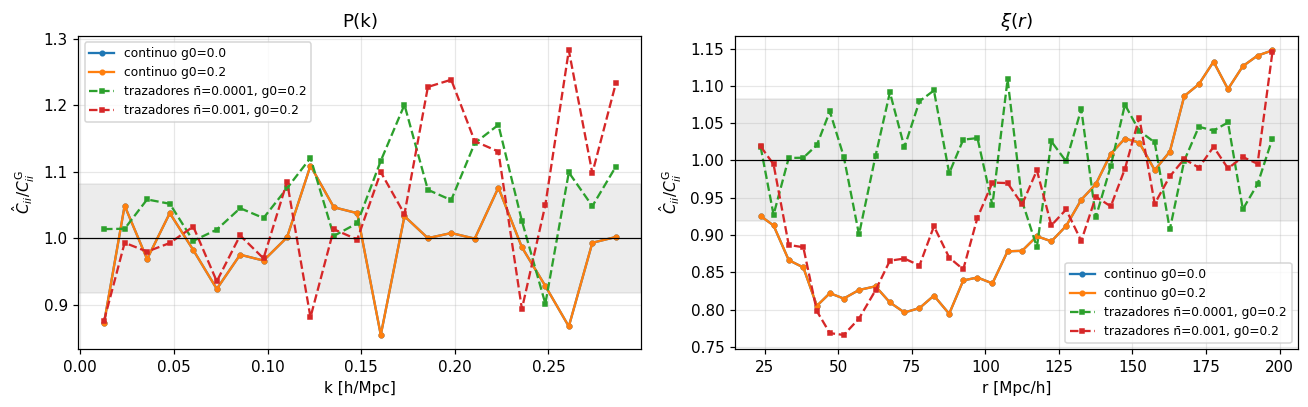

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for g0 in [0.0, G0_FID]:
    ax[0].plot(k_b, np.diag(SC_P[g0])/np.diag(GC_P[g0]), "o-", ms=3, label=f"continuo g0={g0}")
    ax[1].plot(r_b, np.diag(SC_X[g0])/np.diag(GC_X[g0]), "o-", ms=3, label=f"continuo g0={g0}")
for nb in NBAR:
    key = (G0_FID, nb)
    ax[0].plot(k_b, np.diag(SCt_P[key])/np.diag(GCt_P[key]), "s--", ms=3, label=f"trazadores n̄={nb:g}, g0={G0_FID}")
    ax[1].plot(r_b, np.diag(SCt_X[key])/np.diag(GCt_X[key]), "s--", ms=3, label=f"trazadores n̄={nb:g}, g0={G0_FID}")
for a in ax:
    a.axhline(1, color="k", lw=0.8)
    a.axhspan(1 - np.sqrt(2/(Ns_tr - 1)), 1 + np.sqrt(2/(Ns_tr - 1)), color="gray", alpha=0.15)
    a.legend(fontsize=8)
ax[0].set(xlabel="k [h/Mpc]", ylabel=r"$\hat C_{ii}/C^{\rm G}_{ii}$", title="P(k)")
ax[1].set(xlabel="r [Mpc/h]", ylabel=r"$\hat C_{ii}/C^{\rm G}_{ii}$", title=r"$\xi(r)$")
plt.tight_layout(); plt.show()

### 6b. Matrices de correlación

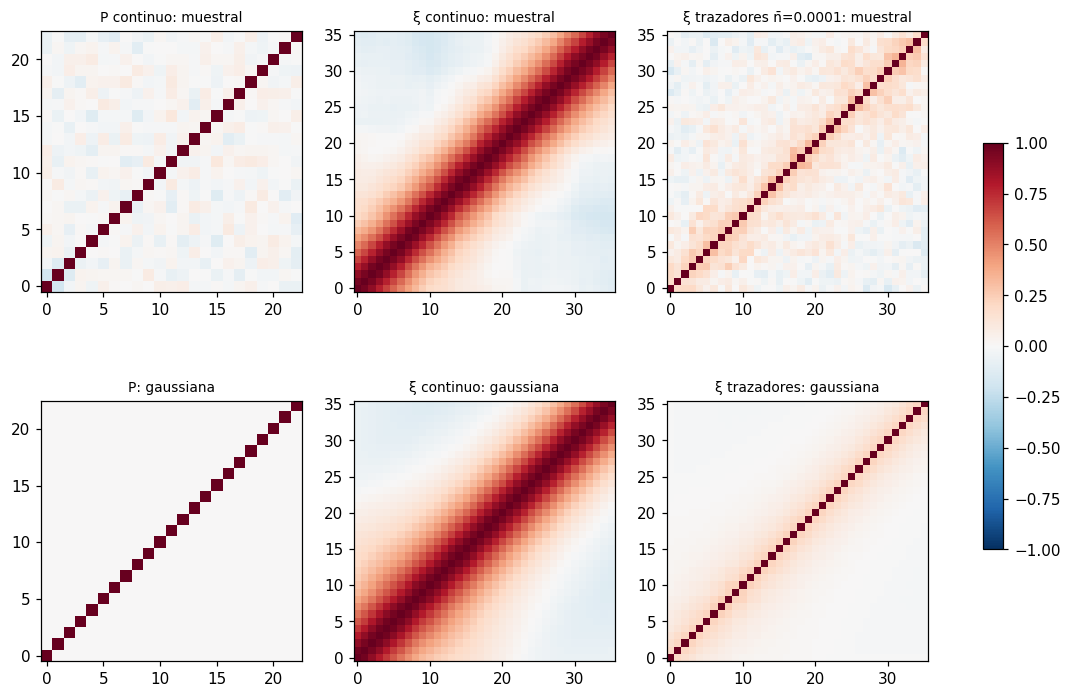

In [19]:
key = (G0_FID, NBAR[0])
mats = [(corr(SC_P[G0_FID]), "P continuo: muestral"), (corr(GC_P[G0_FID]), "P: gaussiana"),
        (corr(SC_X[G0_FID]), "ξ continuo: muestral"), (corr(GC_X[G0_FID]), "ξ continuo: gaussiana"),
        (corr(SCt_X[key]), f"ξ trazadores n̄={key[1]:g}: muestral"), (corr(GCt_X[key]), "ξ trazadores: gaussiana")]
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for a, (Mx, t) in zip(ax.T.ravel(), mats):
    im = a.imshow(Mx, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1); a.set_title(t, fontsize=9); a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()

### 6c. Prueba $\chi^2$ con la covarianza gaussiana

Si la covarianza gaussiana es correcta, $\chi^2_s=(d_s-d_{\rm modelo})^TC_G^{-1}(d_s-d_{\rm modelo})$ sigue una distribución $\chi^2(n_b)$.

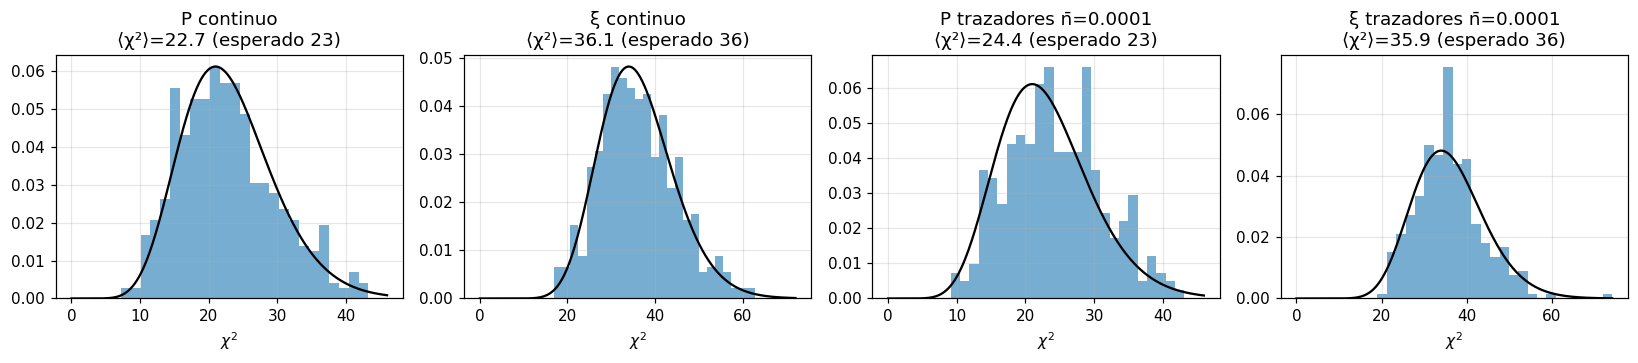

In [20]:
def chi2_samples(X, model, C):
    Pinv = np.linalg.inv(C)
    R_ = X - model
    return np.einsum("si,ij,sj->s", R_, Pinv, R_)

cases = [("P continuo", Pc[G0_FID], PMOD[G0_FID], GC_P[G0_FID]),
         ("ξ continuo", Xc[G0_FID], XMOD[G0_FID], GC_X[G0_FID]),
         (f"P trazadores n̄={NBAR[0]:g}", Pt[G0_FID, NBAR[0]], TR[G0_FID]["Pmod"], GCt_P[G0_FID, NBAR[0]]),
         (f"ξ trazadores n̄={NBAR[0]:g}", Xt[G0_FID, NBAR[0]], TR[G0_FID]["Xmod"], GCt_X[G0_FID, NBAR[0]])]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, (t, X, mod, C) in zip(ax, cases):
    c2 = chi2_samples(X, mod, C); nb_ = len(mod)
    xs = np.linspace(0, max(c2.max(), 2*nb_), 300)
    a.hist(c2, bins=25, density=True, alpha=0.6)
    a.plot(xs, chi2_dist.pdf(xs, nb_), "k-")
    a.set(title=f"{t}\n⟨χ²⟩={c2.mean():.1f} (esperado {nb_})", xlabel=r"$\chi^2$")
plt.tight_layout(); plt.show()

### 6d. Escalamiento con la dilución

En el campo continuo, con la misma semilla, $C(g_0)/C(0)=\mathrm{RATIO}^2=(D^{\rm dil}/D^{\Lambda\rm CDM})^4$ exactamente. Con trazadores **no**: el término $1/\bar n$ no se diluye.

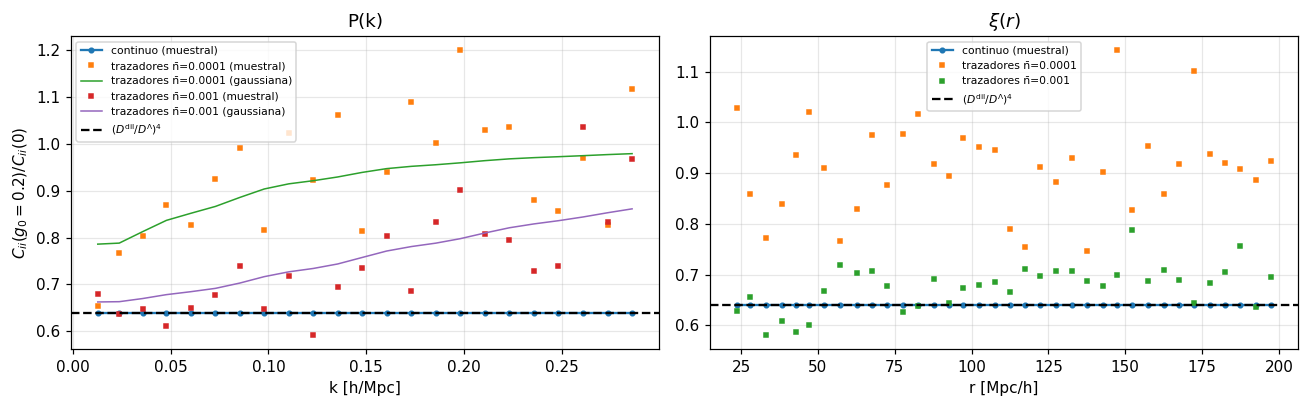

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(k_b, np.diag(SC_P[G0_FID])/np.diag(SC_P[0.0]), "o-", ms=3, label="continuo (muestral)")
ax[1].plot(r_b, np.diag(SC_X[G0_FID])/np.diag(SC_X[0.0]), "o-", ms=3, label="continuo (muestral)")
for nb in NBAR:
    ax[0].plot(k_b, np.diag(SCt_P[G0_FID, nb])/np.diag(SCt_P[0.0, nb]), "s", ms=3, label=f"trazadores n̄={nb:g} (muestral)")
    ax[0].plot(k_b, np.diag(GCt_P[G0_FID, nb])/np.diag(GCt_P[0.0, nb]), "-", lw=1, label=f"trazadores n̄={nb:g} (gaussiana)")
    ax[1].plot(r_b, np.diag(SCt_X[G0_FID, nb])/np.diag(SCt_X[0.0, nb]), "s", ms=3, label=f"trazadores n̄={nb:g}")
for a in ax:
    a.axhline(RATIO[G0_FID]**2, color="k", ls="--", label=r"$(D^{\rm dil}/D^{\Lambda})^4$")
    a.legend(fontsize=7)
ax[0].set(xlabel="k [h/Mpc]", ylabel=r"$C_{ii}(g_0=0.2)/C_{ii}(0)$", title="P(k)")
ax[1].set(xlabel="r [Mpc/h]", title=r"$\xi(r)$")
plt.tight_layout(); plt.show()

## 7. Efecto de la dilución

### 7a. Señal/ruido para distinguir $g_0=0.2$ de ΛCDM

$(S/N)^2(k_{\max})=\Delta^T C^{-1}\Delta$, con $\Delta=P_{\rm mod}(0.2)-P_{\rm mod}(0)$ y la covarianza gaussiana del modelo diluido. Para $\xi$ se usa la covarianza muestral con el factor de Hartlap.

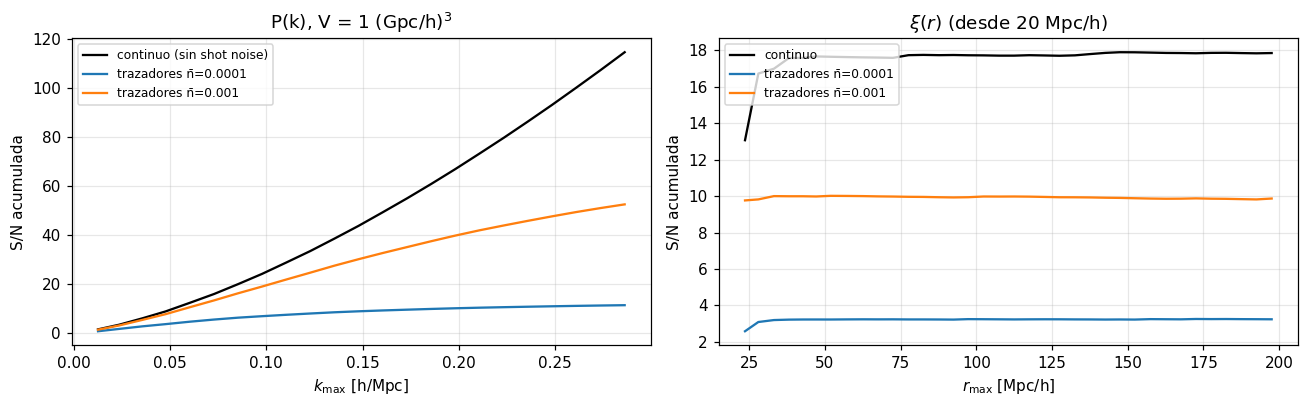

In [22]:
def sn_cumulative(delta, C, Ns_=None):
    # S/N acumulada; si Ns_ se da, C es muestral y se aplica Hartlap a cada submatriz
    out = []
    for m in range(1, len(delta) + 1):
        if Ns_ and m > Ns_ - 3:          # no invertible: más bins que realizaciones
            out.append(np.nan); continue
        fac = (Ns_ - m - 2)/(Ns_ - 1) if Ns_ else 1.0
        out.append(np.sqrt(fac*delta[:m] @ np.linalg.solve(C[:m, :m], delta[:m])))
    return np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(k_b, sn_cumulative(PMOD[G0_FID] - PMOD[0.0], GC_P[G0_FID]), "k-", label="continuo (sin shot noise)")
ax[1].plot(r_b, sn_cumulative(XMOD[G0_FID] - XMOD[0.0], SC_X[G0_FID], Ns), "k-", label="continuo")
for nb in NBAR:
    ax[0].plot(k_b, sn_cumulative(TR[G0_FID]["Pmod"] - TR[0.0]["Pmod"], GCt_P[G0_FID, nb]), label=f"trazadores n̄={nb:g}")
    ax[1].plot(r_b, sn_cumulative(TR[G0_FID]["Xmod"] - TR[0.0]["Xmod"], SCt_X[G0_FID, nb], Ns_tr), label=f"trazadores n̄={nb:g}")
ax[0].set(xlabel=r"$k_{\max}$ [h/Mpc]", ylabel="S/N acumulada", title=r"P(k), V = 1 (Gpc/h)$^3$")
ax[1].set(xlabel=r"$r_{\max}$ [Mpc/h]", ylabel="S/N acumulada", title=r"$\xi(r)$ (desde 20 Mpc/h)")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7b. Comparación de estimadores de $\xi$

Para cada estimador se calcula su varianza dividida entre la de LS con el $\alpha$ más grande, para $g_0=0$ y $g_0=0.2$. **Pregunta:** ¿cambia el desempeño relativo cuando la señal está diluida, es decir con una $\xi$ más chica frente al ruido de disparo?

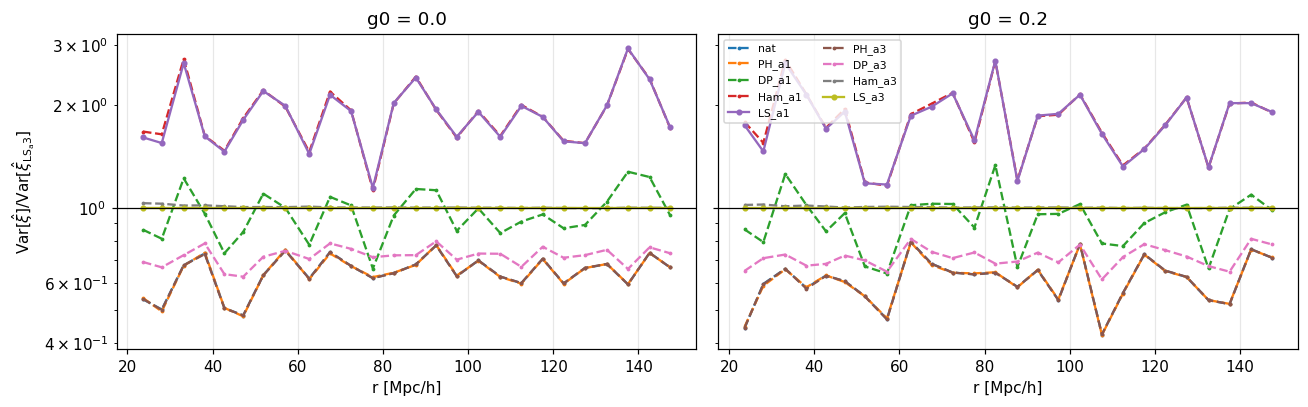

Var promedio relativa a LS_a3 (r = 20–150 Mpc/h); error de cada número ~ 0.18
 estimador  g0=0.0   g0=0.2 
       nat     0.646     0.616
     PH_a1     0.645     0.616
     DP_a1     0.965     0.928
    Ham_a1     1.902     1.819
     LS_a1     1.888     1.807
     PH_a3     0.645     0.616
     DP_a3     0.722     0.716
    Ham_a3     1.005     1.004
     LS_a3     1.000     1.000


In [23]:
ref = f"LS_a{ALPHAS[-1]}"
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, g0 in zip(ax, G_PAIRS):
    vref = EST[g0][ref].var(0, ddof=1)
    for e in EST_NAMES:
        a.plot(rp_b, EST[g0][e].var(0, ddof=1)/vref, "o-" if "LS" in e else ".--", ms=3, label=e)
    a.axhline(1, color="k", lw=0.8)
    a.set(xlabel="r [Mpc/h]", title=f"g0 = {g0}", yscale="log")
ax[0].set_ylabel(r"Var$[\hat\xi]$/Var$[\hat\xi_{\rm %s}]$" % ref)
ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

print(f"Var promedio relativa a {ref} (r = 20–{RMAX_PAIRS:.0f} Mpc/h); error de cada número ~ {np.sqrt(2/(NS_PAIRS-1)):.2f}")
print(f"{'estimador':>10s}" + "".join(f"  g0={g0:<4}" for g0 in G_PAIRS))
for e in EST_NAMES:
    vals = [np.mean(EST[g0][e].var(0, ddof=1)/EST[g0][ref].var(0, ddof=1)) for g0 in G_PAIRS]
    print(f"{e:>10s}" + "".join(f"  {v:8.3f}" for v in vals))

### 7c. Dependencia de la covarianza con $g_0$ (estilo Steele & Smith)

Al estilo de Steele & Smith, se usa una aproximación lineal en el parámetro, $C(g_0)\simeq C(0)+g_0\,\partial C/\partial g_0$, y la "respuesta" $R=C(0)^{-1}\partial C/\partial g_0$. En el campo continuo, $R=4\,\partial\ln D_+/\partial g_0\,\mathbb 1$; con trazadores depende de la escala.

‖C_lin(0.1) − C(0.1)‖/‖C(0.1)‖ = 0.0108   (usar C(0) fija: 0.1317)


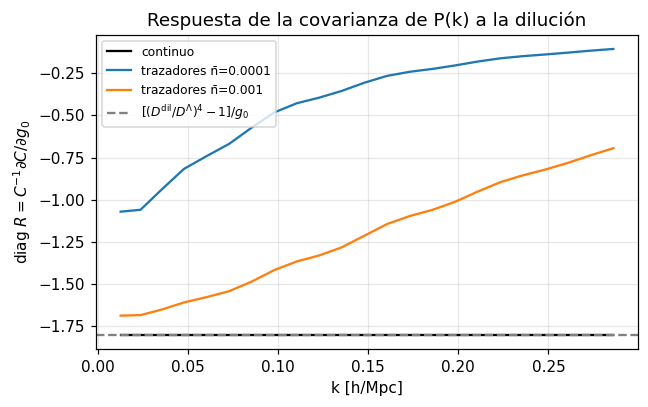

In [24]:
nb = NBAR[0]
dC_P = (GCt_P[G0_FID, nb] - GCt_P[0.0, nb])/G0_FID
C_lin = GCt_P[0.0, nb] + 0.1*dC_P
err_lin = np.linalg.norm(C_lin - GCt_P[0.1, nb])/np.linalg.norm(GCt_P[0.1, nb])
err_fix = np.linalg.norm(GCt_P[0.0, nb] - GCt_P[0.1, nb])/np.linalg.norm(GCt_P[0.1, nb])
print(f"‖C_lin(0.1) − C(0.1)‖/‖C(0.1)‖ = {err_lin:.4f}   (usar C(0) fija: {err_fix:.4f})")

R_cont = np.diag(np.linalg.solve(GC_P[0.0], (GC_P[G0_FID] - GC_P[0.0])/G0_FID))
R_tr = {nb_: np.diag(np.linalg.solve(GCt_P[0.0, nb_], (GCt_P[G0_FID, nb_] - GCt_P[0.0, nb_])/G0_FID)) for nb_ in NBAR}
plt.figure(figsize=(6, 3.8))
plt.plot(k_b, R_cont, "k-", label="continuo")
for nb_ in NBAR: plt.plot(k_b, R_tr[nb_], label=f"trazadores n̄={nb_:g}")
plt.axhline((RATIO[G0_FID]**2 - 1)/G0_FID, color="gray", ls="--", label=r"$[(D^{\rm dil}/D^\Lambda)^4-1]/g_0$")
plt.xlabel("k [h/Mpc]"); plt.ylabel(r"diag $R = C^{-1}\partial C/\partial g_0$"); plt.legend(fontsize=8)
plt.title("Respuesta de la covarianza de P(k) a la dilución"); plt.tight_layout(); plt.show()

### 7d. ¿Qué pasa si se usa la covarianza de ΛCDM para datos diluidos?

Se ajusta una amplitud $A$ con la plantilla $S=P_{\rm mod}(g_0=0)$ a cada realización diluida de trazadores:
$$\hat A=\frac{S^T\Psi d}{S^T\Psi S},\qquad \sigma_A=(S^T\Psi S)^{-1/2}.$$
Se compara el $\sigma_A$ que predice cada covarianza con la dispersión real de $\hat A$.

In [25]:
S_ = TR[0.0]["Pmod"]
print(f"A esperado ≈ {np.mean(TR[G0_FID]['Pmod']/S_):.4f}  (RATIO = {RATIO[G0_FID]:.4f})")
print(f"{'n̄':>8s} {'cov usada':>12s} {'⟨Â⟩':>8s} {'std(Â) real':>12s} {'σ_A predicho':>13s} {'cociente':>9s}")
for nb_ in NBAR:
    X = Pt[G0_FID, nb_]
    for lab, C in [("dilución", GCt_P[G0_FID, nb_]), ("ΛCDM", GCt_P[0.0, nb_])]:
        Psi = np.linalg.inv(C)
        A_hat = (X @ Psi @ S_)/(S_ @ Psi @ S_)
        sA = 1/np.sqrt(S_ @ Psi @ S_)
        print(f"{nb_:8.0e} {lab:>12s} {A_hat.mean():8.4f} {A_hat.std(ddof=1):12.5f} {sA:13.5f} {sA/A_hat.std(ddof=1):9.3f}")

A esperado ≈ 0.7999  (RATIO = 0.7999)
      n̄    cov usada      ⟨Â⟩  std(Â) real  σ_A predicho  cociente
   1e-04     dilución   0.7988      0.02181       0.01748     0.801
   1e-04         ΛCDM   0.7988      0.02189       0.01827     0.834
   1e-03     dilución   0.8008      0.00555       0.00380     0.685
   1e-03         ΛCDM   0.8008      0.00556       0.00429     0.772


## 8. Resumen y qué reportar

Leer los resultados en este orden:
1. **Validación (6a–6c, continuo):** la covarianza muestral del campo gaussiano debe coincidir con la gaussiana analítica dentro de $\sqrt{2/N_s}$, y $\langle\chi^2\rangle\approx n_b$. Esto valida el código.
2. **Trazadores (6a–6c):** las desviaciones respecto a la gaussiana miden la parte no gaussiana (lognormal + Poisson). Hay que ver si dependen de $\bar n$ y de $g_0$.
3. **Escalamiento (6d):** en el continuo se tiene exactamente $(D^{\rm dil}/D^\Lambda)^4$. Con trazadores el escalamiento se rompe a $k$ grande, donde domina $1/\bar n$.
4. **S/N (7a):** cuánta información hay para distinguir la dilución en un volumen de 1 (Gpc/h)³.
5. **Estimadores (7b):** la ventaja usual de LS viene de corregir los bordes de la geometría del catálogo. En una caja periódica no hay bordes, así que no tiene por qué aparecer: hay que ver si PH o el estimador natural resultan iguales o mejores. Con aleatorios **fijos**, PH tiene la misma varianza que el natural, porque RR es un factor constante; LS y Hamilton agregan el ruido de DR.
6. **Covarianza equivocada (7c–7d):** usar $C_{\Lambda\rm CDM}$ en datos diluidos sobreestima el error, porque $C_{\Lambda\rm CDM}$ tiene más varianza cósmica.

**Limitaciones:** solo orden lineal y espacio real, una sola caja de $V=1\,(h^{-1}{\rm Gpc})^3$, trazadores lognormales (no es gravedad real) y sin RSD.